# 実効値(True RMS)

交流の大きさを 1 つの数で表すのが**実効値**(RMS:root mean square)です。抵抗につないだときに、同じ電力になる直流の電圧で、家のコンセントの 100 V も実効値です。正弦波なら振幅の $1/\sqrt{2}$ ですが、波形が違うと振幅との比も変わります。

安いテスターの多くは、整流(5-4)して平均した値に、正弦波で合うように 1.111 を掛けて表示します(**平均値方式**)。正弦波ではこれで正しいのですが、方形波や三角波、ひずんだ波形ではずれます。名前どおり「2 乗の平均の平方根」を計算する回路を **True RMS**(真の実効値)といい、その IC(AD636、LTC1966 など)を使ったテスターは「True RMS」と書かれています。

この回では、3 つの波形の実効値と平均値方式の差、平均の時定数とリプル、入力が変わったときの応答の速さ、の 3 つを見ます。

## 回路

![True RMS(ブロック図)](03_rms/circuit.svg)

定義どおり、2 乗する(7-2)→ 平均する(コンデンサで LPF、2-1)→ 平方根をとる(7-2)、の順に計算します。ただし、2 乗するとダイナミックレンジ(扱える大きさの比)が 2 乗で広がってしまうので、IC では対数と逆対数(7-1)を組み合わせて、2 乗と平方根をまとめて計算します(陰関数の方式)。平均の時定数は、外づけのコンデンサで決めます。

## 原理

$$V_\mathrm{rms} = \sqrt{\overline{d^2}}, \qquad d = V_\mathrm{in} - V_\mathrm{ref}$$

| 波形(振幅 A) | 実効値 | 整流の平均 $\overline{|d|}$ | 平均値方式(× 1.111) | ずれ |
|---|---|---|---|---|
| 正弦波 | $A/\sqrt{2}$ = 0.707 A | $2A/\pi$ = 0.637 A | 0.707 A | 0 % |
| 三角波 | $A/\sqrt{3}$ = 0.577 A | $A/2$ | 0.555 A | −3.8 % |
| 方形波 | $A$ | $A$ | 1.111 A | +11.1 % |

![実効値と平均値方式(模式図)](03_rms/response.svg)

**時定数**:Mimic の True RMS は、2 乗を時定数 τ の 1 次 LPF で平均します。平均しきれない 2 乗の振れ(正弦波なら 2 倍の周波数)が、出力の**リプル**として残ります。周波数 f の正弦波では、リプルの山から谷はおよそ実効値 × $1/\sqrt{1 + (4\pi f \tau)^2}$ です。τ を長くするとリプルは減りますが、入力が変わったときに出力が落ち着くまでの時間(1 % に入るまで約 4τ)が長くなります。

Mimic の出力は **0 V からの大きさ**(ゲイン 1)です。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.true_rms(time_us)` | `mimic.setTrueRms(time_us)` | 平均の時定数(µs、10 µs〜10 s)。RMS 変換 IC の平均用のコンデンサにあたる |

- デシメーションなしで使います(デシメーションは DSP の前に入力を平均してしまうため)。
- 下の準備のセルの `show_rms` は、入力と出力の波形に、比べる値を横線で描きます。`from_input` は、測定器が取り込んだ入力(CH1)から、実効値と平均値方式の値を計算します(CH1 の平均を中心にするので、直流は除きます)。比べるための「ものさし」です。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.5, mimic=20261125)

In [2]:
FORM = np.pi / (2 * np.sqrt(2))   # rms / mean |d| of a sine: 1.111


def from_input(ch1):
    # The RMS and the reading of an average-responding meter, computed from CH1 (the
    # mean of CH1 is the center: the DC part is left out)
    d = ch1 - ch1.mean()
    return np.sqrt(np.mean(d**2)), np.mean(np.abs(d)) * FORM


def set_wave(wave, freq, amp, center=None):
    getattr(lab.fg, wave)(freq, amp, center)


def show_rms(t, ch1, ch2, lines):
    # The first 20 ms of the input and the output, with horizontal lines {label: volts}
    n = t < 0.02
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(t[n] * 1e3, ch1[n], label="CH1: input")
    ax.plot(t[n] * 1e3, ch2[n], label="CH2: Mimic true RMS")
    for i, (label, v) in enumerate(lines.items()):
        ax.axhline(v, color=f"C{i + 2}", ls="--", label=f"{label}: {v:.3f} V")
    ax.set_ylim(-0.2, 5.2)
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.tight_layout()
    plt.show()

## 実験 1:3 つの波形の実効値

100 Hz、振幅 1 V の正弦波、三角波、方形波を、時定数 100 ms の True RMS に入れます。出力が落ち着くまで 1 秒待ってから取り込み、出力の平均(Mimic の実効値)と、入力から計算した実効値、平均値方式の値を比べます。Mimic の出力は 0.707、0.577、1.000 V になるはずです。

sine    : Mimic 0.710 V, RMS of CH1 0.707 V, average x 1.111 0.707 V (+0.0 %)
triangle: Mimic 0.581 V, RMS of CH1 0.577 V, average x 1.111 0.555 V (-3.8 %)
square  : Mimic 1.001 V, RMS of CH1 0.999 V, average x 1.111 1.110 V (+11.1 %)


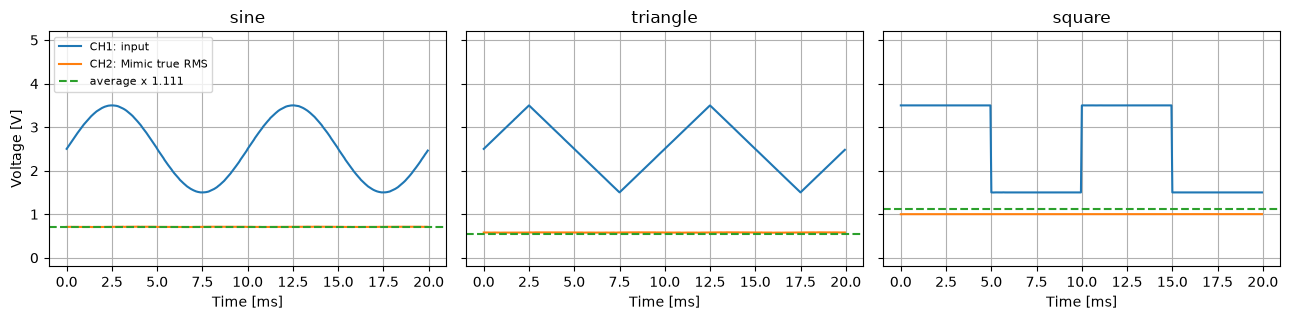

In [3]:
TAU = 100e3   # [us] = 100 ms
lab.mimic.true_rms(TAU)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, wave in zip(axes, ("sine", "triangle", "square")):
    set_wave(wave, 100, 1.0)
    time.sleep(1.0)
    t, ch1, ch2 = lab.scope.capture(2000)
    rms, avg = from_input(ch1)
    print(f"{wave:8s}: Mimic {ch2.mean():.3f} V, RMS of CH1 {rms:.3f} V, "
          f"average x 1.111 {avg:.3f} V ({(avg / rms - 1) * 100:+.1f} %)")
    n = t < 0.02
    ax.plot(t[n] * 1e3, ch1[n], label="CH1: input")
    ax.plot(t[n] * 1e3, ch2[n], label="CH2: Mimic true RMS")
    ax.axhline(avg, color="C2", ls="--", label="average x 1.111")
    ax.set_title(wave)
    ax.set_ylim(-0.2, 5.2)
    ax.set_xlabel("Time [ms]")
    ax.grid(True)
axes[0].set_ylabel("Voltage [V]")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Mimic の出力は、どの波形でも入力から計算した実効値と 1 % 以内で合います。平均値方式は、正弦波では同じ値ですが、三角波では 4 % ほど小さく、方形波では 11 % 大きく出ます。平均値方式のテスターで方形波やインバータの出力を測ると、このように間違えます。

## 実験 2:時定数とリプル

20 Hz、振幅 1 V の正弦波を、時定数 10 ms と 100 ms で比べます。10 ms では、2 乗の振れ(40 Hz)が平均しきれず、出力が大きく波打つ(リプル、山から谷で約 0.27 V)はずです。100 ms では約 0.03 V に減ります。

tau  10 ms: mean 0.704 V, ripple 0.272 V peak to peak (theory 0.266 V)
tau 100 ms: mean 0.710 V, ripple 0.033 V peak to peak (theory 0.028 V)


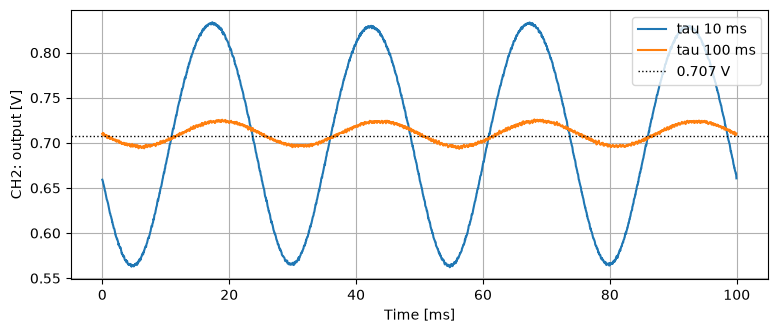

In [4]:
lab.fg.sine(20, 1.0)
fig, ax = plt.subplots(figsize=(9, 3.5))
for tau_ms in (10, 100):
    lab.mimic.true_rms(tau_ms * 1e3)
    time.sleep(1.0)
    t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s: 2 periods of the input
    theory = 0.707 * (np.sqrt(1 + 1 / np.hypot(1, 4 * np.pi * 20 * tau_ms * 1e-3))
                      - np.sqrt(1 - 1 / np.hypot(1, 4 * np.pi * 20 * tau_ms * 1e-3)))
    print(f"tau {tau_ms:3d} ms: mean {ch2.mean():.3f} V, ripple {np.ptp(ch2):.3f} V peak to peak (theory {theory:.3f} V)")
    ax.plot(t * 1e3, ch2, label=f"tau {tau_ms} ms")
ax.axhline(1 / np.sqrt(2), color="k", ls=":", lw=1, label="0.707 V")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("CH2: output [V]")
ax.grid(True)
ax.legend(loc="upper right")
plt.show()

10 ms では、出力が 40 Hz(入力の 2 倍)で大きく波打ち、平均も 0.707 V から少しずれます(波打つ 2 乗の平方根をとるため)。100 ms では、ほぼ平らです。リプルを小さくするには、時定数を測りたい周波数の周期より十分長くします。

## 実験 3:応答の速さ

入力を 2.5 V の直流(実効値 0)にして待ったあと、100 Hz、振幅 1 V の正弦波に切り替え、すぐに 2 kHz で 1 秒取り込みます。時定数 100 ms では、出力は $0.707\sqrt{1 - e^{-t/\tau}}$ に沿って上がり、0.4〜0.5 秒ほどでほぼ 0.707 V に落ち着くはずです。

settled 0.710 V; within 1 % after 462 ms (theory 392 ms)


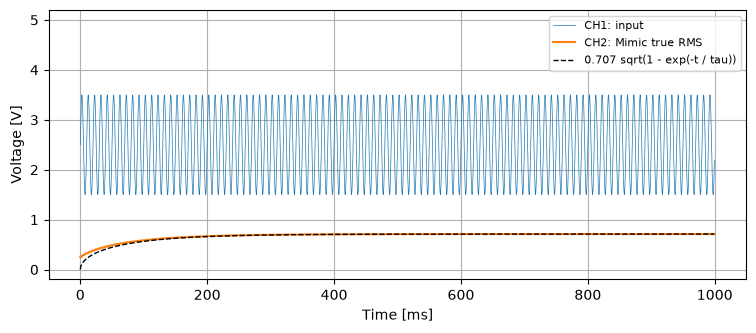

In [5]:
TAU_MS = 100
lab.mimic.true_rms(TAU_MS * 1e3)
lab.fg.dc(2.5)
time.sleep(1.0)
lab.fg.sine(100, 1.0)
t, ch1, ch2 = lab.scope.capture(2000, fs=2000)   # 1 s
settled = ch2[t > 0.8].mean()
i99 = np.flatnonzero(ch2 < 0.99 * settled)
print(f"settled {settled:.3f} V; within 1 % after {t[i99[-1]] * 1e3 if len(i99) else 0:.0f} ms "
      f"(theory {TAU_MS * np.log(1 / (1 - 0.99**2)):.0f} ms)")
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t * 1e3, ch1, lw=0.5, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: Mimic true RMS")
ax.plot(t * 1e3, settled * np.sqrt(1 - np.exp(-t / (TAU_MS * 1e-3))), "k--", lw=1,
        label="0.707 sqrt(1 - exp(-t / tau))")
ax.set_ylim(-0.2, 5.2)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend(loc="upper right", fontsize=8)
plt.show()

出力は、はじめ速く、あとはゆっくり、落ち着いた値に近づきます(取り込みは、正弦波に切り替えてから波形の始まりを待って 10 ms ほどあとに始まるので、出力は 0 ではなく少し上から始まります)。平均されているのは 2 乗なので、2 乗が $1 - e^{-t/\tau}$ に沿って増え、出力はその平方根です。1 % に入るまでには、時定数の約 4 倍かかります。速く応答させたいときは時定数を短く、リプルを減らしたいときは長くします。RMS 変換 IC のデータシートでも、測りたい最低の周波数に合わせて平均用のコンデンサを選びます。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 波形と振幅
<details><summary>ヒント</summary>

はじめは `WAVE = "triangle"`、`AMP = 1.0` です。`AMP` を 0.5 → 1.5 と変えてみましょう。実効値は振幅に比例します(三角波で 0.289、0.866 V)。`WAVE` を `"square"` や `"sine"` にして、平均値方式とのずれが振幅によらないことも確かめましょう(ずれは波形の形だけで決まります)。

</details>

Mimic 0.581 V, RMS of CH1 0.577 V, average x 1.111 0.555 V (-3.8 %)


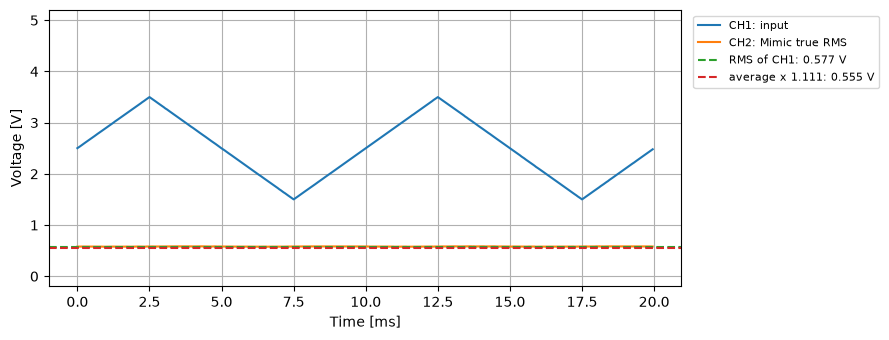

In [6]:
WAVE = "triangle"   # "sine", "triangle" or "square"
AMP = 1.0           # [V]

lab.mimic.true_rms(100e3)
set_wave(WAVE, 100, AMP)
time.sleep(1.0)
t, ch1, ch2 = lab.scope.capture(2000)
rms, avg = from_input(ch1)
print(f"Mimic {ch2.mean():.3f} V, RMS of CH1 {rms:.3f} V, average x 1.111 {avg:.3f} V ({(avg / rms - 1) * 100:+.1f} %)")
show_rms(t, ch1, ch2, {"RMS of CH1": rms, "average x 1.111": avg})

### 2. 周波数と時定数
<details><summary>ヒント</summary>

はじめは `FREQ = 20`、`TAU_MS = 30` です(リプル約 0.09 V)。`FREQ` を 50 → 200 と上げると、リプルは小さくなります(約 0.04、0.01 V)。`FREQ = 20` に戻して `TAU_MS` を 3 → 300 と変えると、3 ms では出力がほとんど |入力| の形(全波整流に近い形)で波打ち、300 ms ではほぼ平らになります。時定数を変えたら、落ち着くまで(4τ 以上)待ってから取り込みます(セルの中で待っています)。

</details>

mean 0.710 V, ripple 0.097 V peak to peak (theory 0.093 V)


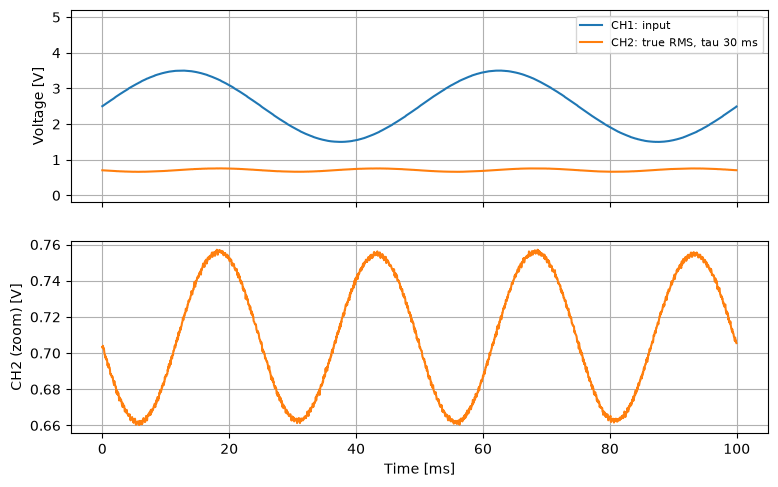

In [7]:
FREQ = 20      # [Hz]
TAU_MS = 30    # [ms]

lab.fg.sine(FREQ, 1.0)
lab.mimic.true_rms(TAU_MS * 1e3)
time.sleep(max(0.2, 5 * TAU_MS * 1e-3))
t, ch1, ch2 = lab.scope.capture(2000)
a = 1 / np.hypot(1, 4 * np.pi * FREQ * TAU_MS * 1e-3)
print(f"mean {ch2.mean():.3f} V, ripple {np.ptp(ch2):.3f} V peak to peak "
      f"(theory {0.707 * (np.sqrt(1 + a) - np.sqrt(1 - a)):.3f} V)")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
ax1.plot(t * 1e3, ch1, label="CH1: input")
ax1.plot(t * 1e3, ch2, label=f"CH2: true RMS, tau {TAU_MS} ms")
ax1.set_ylim(-0.2, 5.2)
ax1.set_ylabel("Voltage [V]")
ax1.legend(loc="upper right", fontsize=8)
ax2.plot(t * 1e3, ch2, color="C1")
ax2.set_ylabel("CH2 (zoom) [V]")
ax2.set_xlabel("Time [ms]")
for ax in (ax1, ax2):
    ax.grid(True)
plt.show()

### 3. 直流も実効値に入る

ここまでは入力の中心が Vref(2.5 V)でした。中心をずらすと、Vref からの直流のずれも実効値に入ります。
<details><summary>ヒント</summary>

はじめは `CENTER = 2.5` です。`CENTER` を 3.0 → 2.0 → 3.5 と変えてみましょう。直流 D と交流の実効値 $V_\mathrm{ac}$ を合わせた実効値は $\sqrt{D^2 + V_\mathrm{ac}^2}$ で、3.0 V(D = 0.5 V)では $\sqrt{0.25 + 0.5}$ = 0.866 V になります。2.0 V でも同じです(2 乗するので向きによらない)。`AMP = 0` にすると直流だけになり、出力は |D| です。テスターの「AC」のレンジは直流を除いた実効値(`from_input` と同じ)を、「AC+DC」のレンジはこの値を表示します。

</details>

Mimic 0.710 V; from CH1: DC +0.000 V, AC 0.707 V, sqrt(DC^2 + AC^2) 0.707 V


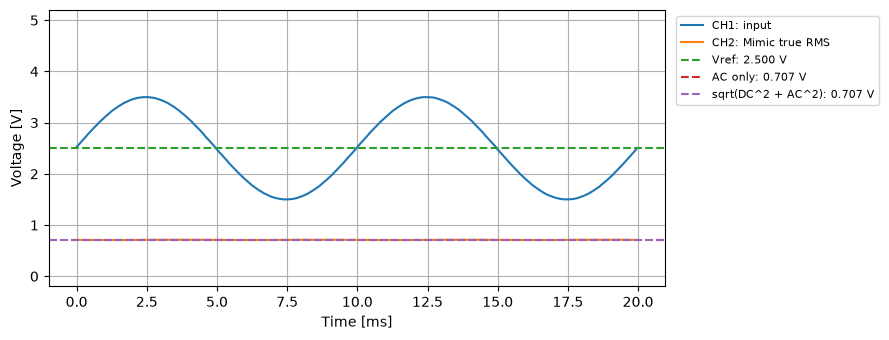

In [8]:
CENTER = 2.5   # [V] the center of the input sine
AMP = 1.0      # [V]

lab.mimic.true_rms(100e3)
if AMP > 0:
    lab.fg.sine(100, AMP, CENTER)
else:
    lab.fg.dc(CENTER)
time.sleep(1.0)
t, ch1, ch2 = lab.scope.capture(2000)
dc = ch1.mean() - 2.5
ac = np.sqrt(np.mean((ch1 - ch1.mean())**2))
print(f"Mimic {ch2.mean():.3f} V; from CH1: DC {dc:+.3f} V, AC {ac:.3f} V, "
      f"sqrt(DC^2 + AC^2) {np.hypot(dc, ac):.3f} V")
show_rms(t, ch1, ch2, {"Vref": 2.5, "AC only": ac, "sqrt(DC^2 + AC^2)": np.hypot(dc, ac)})

## まとめ

- 実効値は、抵抗で同じ電力になる直流の電圧。2 乗の平均の平方根。正弦波は振幅 × 0.707、三角波 × 0.577、方形波 × 1。
- 平均値方式(整流の平均 × 1.111)は正弦波でしか正しくない。三角波で −3.8 %、方形波で +11.1 %。
- True RMS は 2 乗 → 平均 → 平方根。平均の時定数で、リプルと応答の速さが決まる。
- 直流のずれも実効値に入る(AC+DC)。
- Mimic では `true_rms(time_us)`。出力は 0 V からの大きさ。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()